# Building-damage class distribution across datasets

This notebook reproduces the grouped horizontal bar chart used in the manuscript. Change `FIGURE_WIDTH`, `FIGURE_HEIGHT`, and `EXPORT_DPI` in the next cell to control its size and resolution. The chart is exported as PNG, PDF, and SVG.

In [7]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Adjust these values if you want an even larger figure.
FIGURE_WIDTH = 15
FIGURE_HEIGHT = 9
EXPORT_DPI = 400

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "output/RSBDNet_dataset_statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_STEM = OUTPUT_DIR / "building_damage_statistics_large"

## Class counts

Each value is the number of labeled connected building components for the corresponding damage class.

In [9]:
class_labels = ["No damage", "Minor damage", "Major damage", "Destroyed"]
colors = ["#20B2C1", "#18A64A", "#225EA8", "#EF2B2D"]

dataset_counts = {
    "xBD": [211_623, 29_424, 24_280, 25_322],
    "Earthquake Turkey": [16_759, 228, 157, 363],
    "Pakistan Flooding": [9_258, 1_399, 493, 1_825],
    "Hurricane Delta": [6_279, 1_630, 613, 432],
    "Mount Semeru Eruption": [2_820, 647, 190, 71],
    "Texas Tornadoes": [2_650, 23, 42, 88],
}

dataset_counts

{'xBD': [211623, 29424, 24280, 25322],
 'Earthquake Turkey': [16759, 228, 157, 363],
 'Pakistan Flooding': [9258, 1399, 493, 1825],
 'Hurricane Delta': [6279, 1630, 613, 432],
 'Mount Semeru Eruption': [2820, 647, 190, 71],
 'Texas Tornadoes': [2650, 23, 42, 88]}

## Generate the enlarged figure

Saved: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_dataset_statistics/building_damage_statistics_large.png
Saved: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_dataset_statistics/building_damage_statistics_large.pdf
Saved: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_dataset_statistics/building_damage_statistics_large.svg


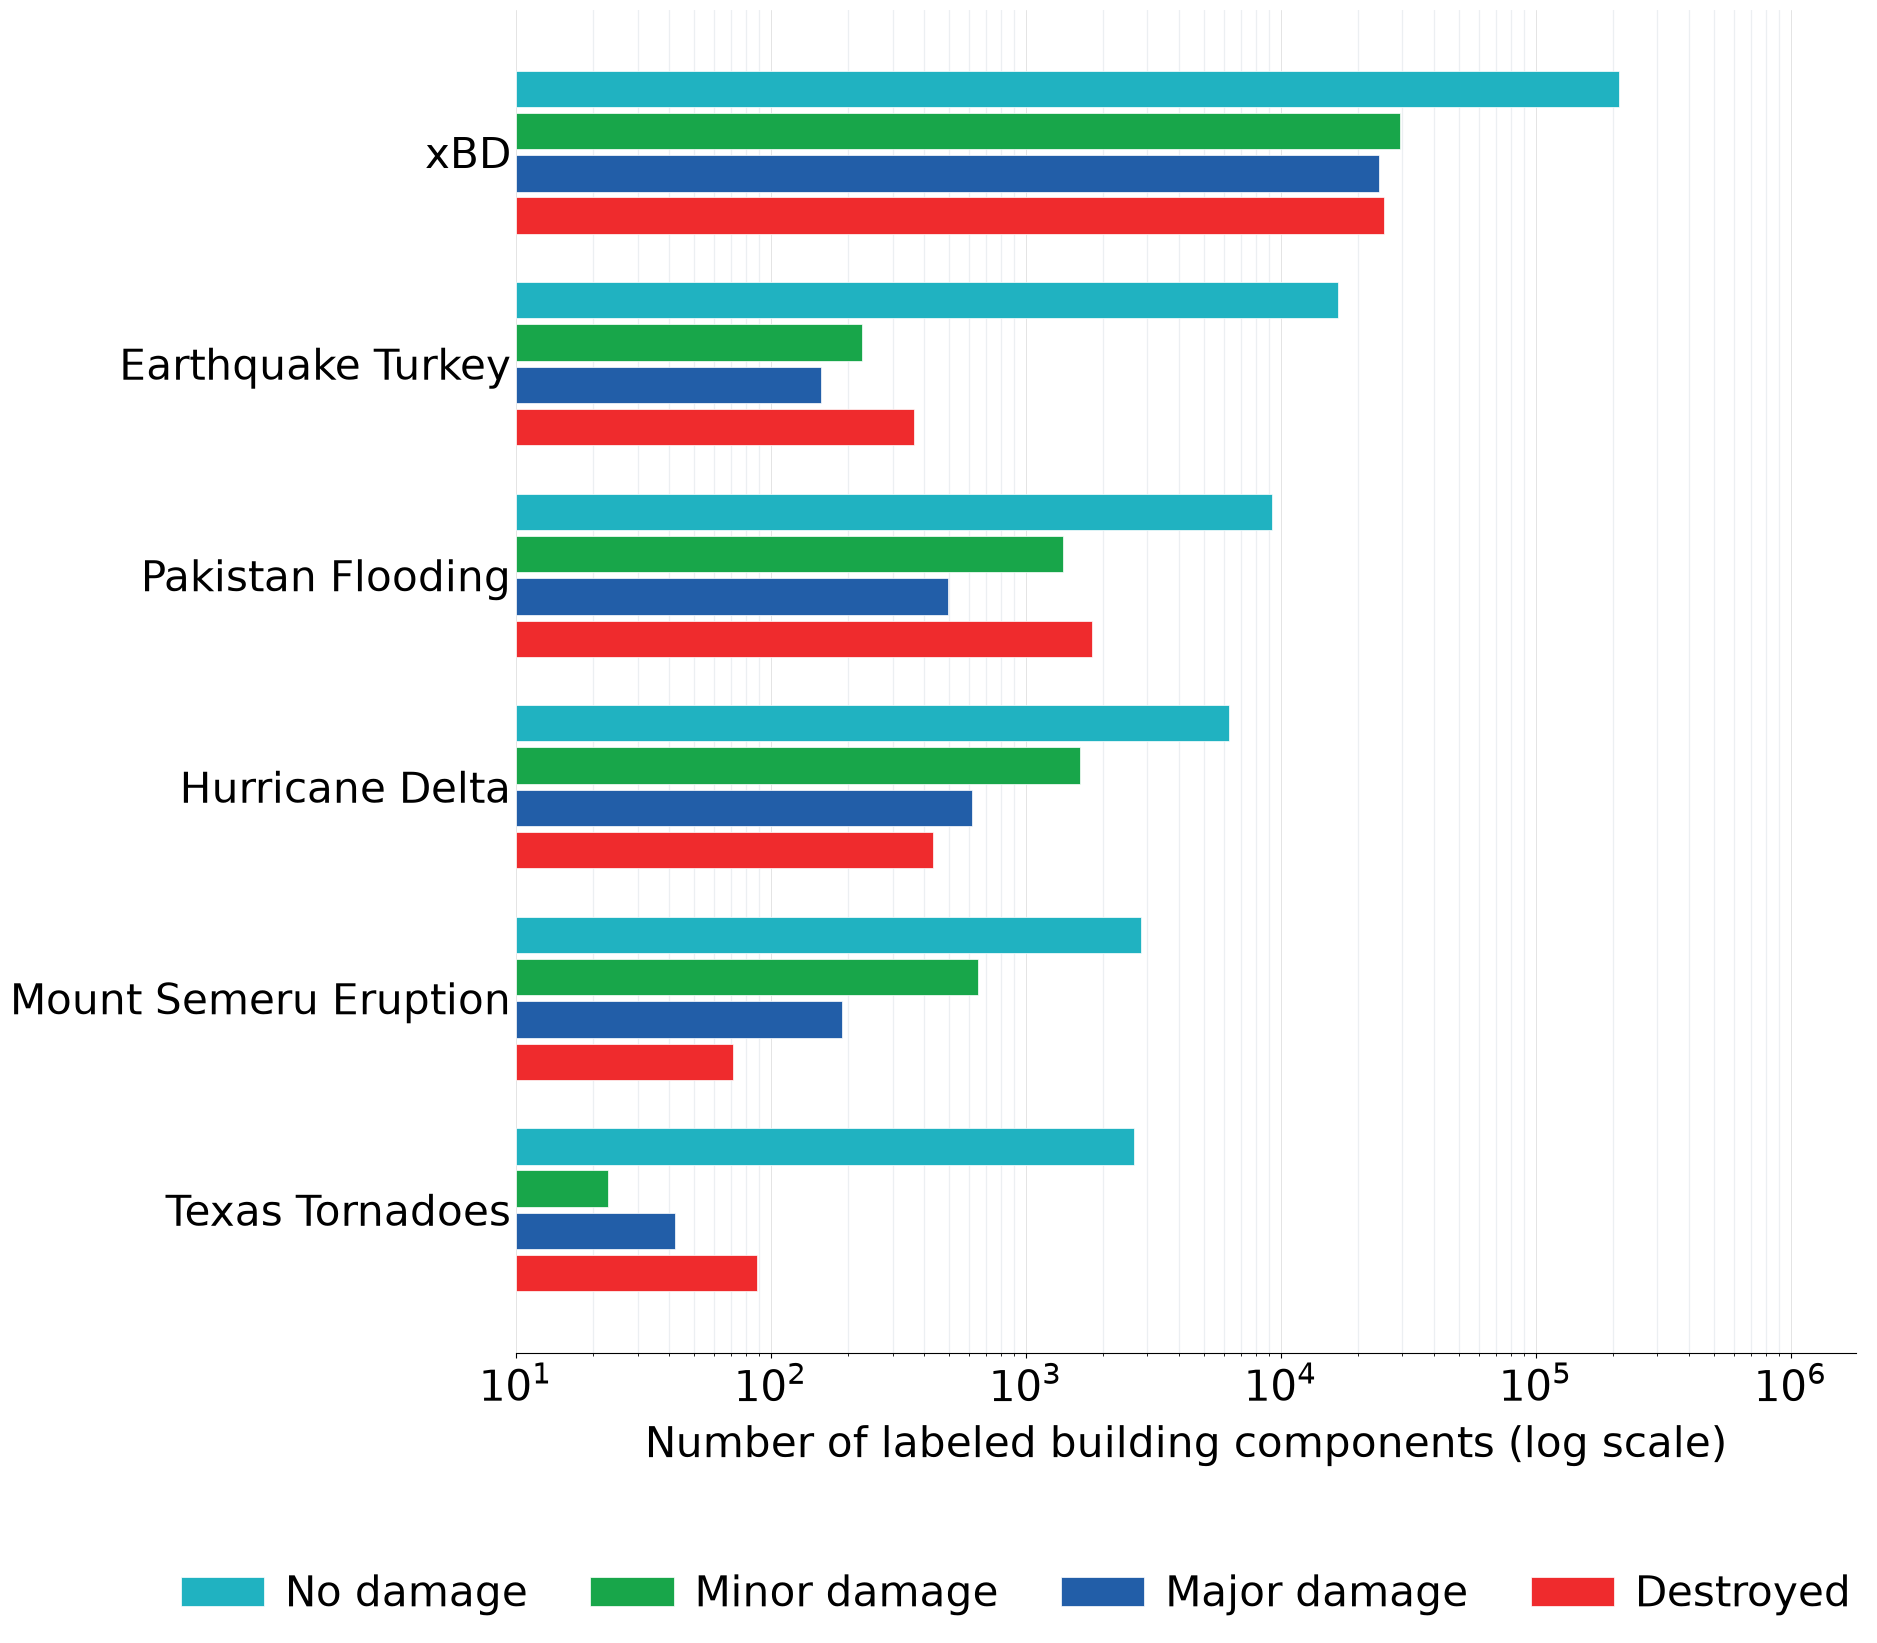

In [10]:
# ============================================================
# Figure settings
# ============================================================

FIGURE_WIDTH = 20
FIGURE_HEIGHT = 17
FONT_SIZE = 30

names = list(dataset_counts.keys())
counts = np.asarray(list(dataset_counts.values()), dtype=float)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(
    figsize=(FIGURE_WIDTH, FIGURE_HEIGHT)
)

# ============================================================
# Bar positions
# ============================================================

group_centers = np.arange(len(names), dtype=float)

bar_height = 0.20
offsets = np.array([-1.5, -0.5, 0.5, 1.5]) * bar_height

positive_counts = counts[counts > 0]

x_min = max(
    1.0,
    10.0 ** np.floor(np.log10(positive_counts.min()))
)

x_max = 10.0 ** np.ceil(
    np.log10(positive_counts.max())
)

# ============================================================
# Plot grouped points
# ============================================================

for class_index, (label, color) in enumerate(
    zip(class_labels, colors)
):

    values = counts[:, class_index]
    positions = group_centers + offsets[class_index]

    ax.scatter(
        values,
        positions,
        s=430,
        color=color,
        label=label,
        edgecolor="white",
        linewidth=1.8,
        zorder=3,
    )

# ============================================================
# Y-axis: Dataset names
# ============================================================

ax.set_yticks(group_centers, names)

ax.tick_params(
    axis="y",
    labelsize=FONT_SIZE,
    length=0
)

ax.invert_yaxis()

# ============================================================
# X-axis
# ============================================================

ax.set_xscale("log")

# Compact logarithmic range; no room is needed for numeric annotations.
ax.set_xlim(
    x_min,
    x_max * 1.20
)

ax.tick_params(
    axis="x",
    labelsize=FONT_SIZE
)

ax.set_xlabel(
    "Number of labeled building components (log scale)",
    fontsize=FONT_SIZE,
    labelpad=10
)

# ============================================================
# Grid
# ============================================================

ax.grid(
    axis="x",
    which="major",
    color="#D9D9D9",
    linewidth=0.5
)

ax.grid(
    axis="x",
    which="minor",
    color="#ECEFF2",
    linewidth=0.9
)

ax.set_axisbelow(True)

# ============================================================
# Remove unnecessary borders
# ============================================================

ax.spines[["top", "right", "left"]].set_visible(False)

# ============================================================
# Legend BELOW the figure
# ============================================================

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,

    # Put legend at bottom center
    loc="lower center",

    # Horizontal position = 0.5 (center)
    # Vertical position controls how low the legend is
    bbox_to_anchor=(0.5, 0.015),

    # Put all four classes on one row
    ncol=4,

    frameon=False,
    fontsize=FONT_SIZE,

    borderaxespad=0.0,
    columnspacing=1.5,
    handletextpad=0.5,
)

# ============================================================
# Layout
# ============================================================

fig.subplots_adjust(
    top=0.97,

    # More space at bottom for x-axis label + legend
    bottom=0.18,

    left=0.25,
    right=0.92
)

# ============================================================
# Save figure
# ============================================================

fig.savefig(
    OUTPUT_STEM.with_suffix(".png"),
    dpi=EXPORT_DPI,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_STEM.with_suffix(".pdf"),
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_STEM.with_suffix(".svg"),
    bbox_inches="tight",
    facecolor="white"
)

print(f"Saved: {OUTPUT_STEM.with_suffix('.png')}")
print(f"Saved: {OUTPUT_STEM.with_suffix('.pdf')}")
print(f"Saved: {OUTPUT_STEM.with_suffix('.svg')}")

plt.show()